# Diviser pour régner — Exercice 7 : tourner une image d'un quart de tour (correction)

Ce notebook contient, pour chaque question, trois blocs **toujours séparés** :

| Bloc | Contenu |
|:---|:---|
| 📝 **ÉNONCÉ** | la question, recopiée du sujet |
| ✅ **RÉSOLUTION** | la réponse attendue (code et/ou texte) |
| 💡 **EXPLICATION PÉDAGOGIQUE** | pourquoi ça marche, le lien avec le cours, les erreurs à éviter. **N'est pas à recopier.** |

**Notions travaillées :** parcours d'une image pixel par pixel, copie dans un tableau, coût en mémoire, récursivité sur un carré découpé en 4.

Exécuter les cellules **dans l'ordre** (*Cell → Run All*).

⚠️ **Pour que ce notebook fonctionne partout** (y compris sans pygame ni le fichier image), on **simule** le module `turnbuffon` avec une petite image de 8 × 8 « pixels » affichée en texte. Les fonctions de résolution sont **exactement celles à utiliser avec le vrai module** : la fin du notebook explique comment.

**Convention :** comme dans pygame, `(i, j)` = (colonne, ligne). `i` augmente vers la **droite**, `j` vers le **bas**, et `(0, 0)` est le coin **en haut à gauche**.

---
# EXERCICE 7

#### 📝 ÉNONCÉ

> L'image `turnbuffon.png` de dimensions 512 × 512 pixels a été tournée d'un quart de tour.
> On s'intéresse dans cet exercice à deux manières différentes d'afficher l'image dans son orientation originale.
> On fournit pour cela, un fichier `turnbuffon.py`, qui affiche l'image dans une fenêtre pygame, et permet de la modifier à l'aide des fonctions suivantes.
> - `get_pixel(i, j)` : renvoie la valeur du pixel de coordonnées (i, j)
> - `set_pixel(i, j, val)` : définit la valeur du pixel de coordonnées (i, j)
> - `update()` : rafraîchit l'affichage
> - `execute(f)` : exécute la fonction f durant l'affichage.
>
> Exemple d'utilisation
> ```python
> from turnbuffon import *
>
> def rotation():
>     for i in range(512):
>         p = get_pixel(i, 0)
>         for j in range(200, 300):
>             set_pixel(i, j, p)
>         update()
>
> execute(rotation)
> ```

*Simulation du module `turnbuffon` (non demandée) :*

In [1]:
# ---------- Simulation du module turnbuffon ----------
TAILLE = 8

ORIGINALE = [
    "########",
    "#.......",
    "#.......",
    "######..",
    "#.......",
    "#.......",
    "#.......",
    "#......o",
]

IMAGE = []        # IMAGE[j][i] = pixel de la colonne i, ligne j


def get_pixel(i, j):
    return IMAGE[j][i]


def set_pixel(i, j, val):
    IMAGE[j][i] = val


def update():
    pass          # avec pygame : rafraîchit la fenêtre


def execute(f):
    f()


def montre(titre):
    print(titre)
    for ligne in IMAGE:
        print("  " + " ".join(ligne))
    print()


def remet_image_tournee():
    # l'image de départ : l'originale tournée d'un quart de tour dans le sens inverse des aiguilles d'une montre
    global IMAGE
    IMAGE = [[ORIGINALE[i][TAILLE - 1 - j] for i in range(TAILLE)] for j in range(TAILLE)]


IMAGE_ORIGINALE = [list(ligne) for ligne in ORIGINALE]
IMAGE = IMAGE_ORIGINALE
montre("Image d'origine (ce qu'on veut retrouver) :")
remet_image_tournee()
montre("Image tournée (ce qu'on a au départ) :")

Image d'origine (ce qu'on veut retrouver) :
  # # # # # # # #
  # . . . . . . .
  # . . . . . . .
  # # # # # # . .
  # . . . . . . .
  # . . . . . . .
  # . . . . . . .
  # . . . . . . o

Image tournée (ce qu'on a au départ) :
  # . . . . . . o
  # . . . . . . .
  # . . # . . . .
  # . . # . . . .
  # . . # . . . .
  # . . # . . . .
  # . . # . . . .
  # # # # # # # #



#### 💡 EXPLICATION PÉDAGOGIQUE

**L'exemple d'utilisation de l'énoncé ne tourne rien du tout !** Il sert seulement à montrer l'utilisation des fonctions : pour chaque colonne `i`, il lit le pixel de la **première ligne** et le recopie sur les lignes 200 à 299. On voit donc apparaître une bande horizontale. Le `update()` dans la boucle `for i` rafraîchit l'affichage après chaque colonne : on voit l'image se modifier progressivement.

---
# QUESTION 1
## 1 (a)

#### 📝 ÉNONCÉ

> Écrire une fonction `rotation_tab` pour que l'image soit affichée dans son orientation originale. Pour cela, on stockera dans un tableau l'ensemble des valeurs des pixels, qui seront ensuite affichés dans le bon ordre.

#### ✅ RÉSOLUTION

In [2]:
def rotation_tab():
    N = TAILLE                      # 512 pour la vraie image
    tab = [[get_pixel(i, j) for j in range(N)] for i in range(N)]    # copie : tab[i][j]
    for i in range(N):
        for j in range(N):
            set_pixel(N - 1 - j, i, tab[i][j])
    update()


remet_image_tournee()
execute(rotation_tab)
montre("Après rotation_tab :")
assert IMAGE == IMAGE_ORIGINALE

Après rotation_tab :
  # # # # # # # #
  # . . . . . . .
  # . . . . . . .
  # # # # # # . .
  # . . . . . . .
  # . . . . . . .
  # . . . . . . .
  # . . . . . . o



#### 💡 EXPLICATION PÉDAGOGIQUE

**Idée :**
1. on **copie** toute l'image dans un tableau `tab` ;
2. on réécrit chaque pixel **à sa nouvelle place** en lisant dans la copie.

La copie est **indispensable** : si on écrivait directement dans l'image, on écraserait des pixels **avant de les avoir lus**.

**Où va le pixel `(i, j)` lors d'un quart de tour dans le sens des aiguilles d'une montre ?** Avec $N$ = taille de l'image :
- le coin haut-gauche `(0, 0)` va en haut à droite, en `(N-1, 0)` ;
- la première ligne (`j = 0`) devient la dernière colonne (`i = N-1`) ;
- la première colonne (`i = 0`) devient la première ligne (`j = 0`).

D'où la formule : **`(i, j)` → `(N - 1 - j, i)`**. Pour vérifier une formule de rotation, il suffit de tester **les 4 coins**.

✔ **C'est bien le bon sens pour la vraie image** `turnbuffon.png` (placée dans ce dossier) : le ciel y est à **gauche**, l'image a donc été tournée dans le sens inverse des aiguilles d'une montre, et ce quart de tour dans le sens des aiguilles la remet à l'endroit. `rotation_tab` et `rotation` ont été testées sur la vraie image de 512 × 512 pixels : les deux remettent le ciel en haut et donnent exactement la même image.

## 1 (b)

#### 📝 ÉNONCÉ

> Sachant qu'un pixel est représenté par quatre nombres entiers compris entre 0 et 255 (rouge, vert, bleu et transparence), estimer le coût en mémoire (en Mo) de cette méthode rotation.

#### ✅ RÉSOLUTION

Le tableau contient **tous** les pixels : $512 \times 512 = 262\,144$ pixels. Chaque pixel = 4 nombres entre 0 et 255, et chaque nombre tient sur **1 octet**.

$$262\,144 \times 4 = 1\,048\,576 \text{ octets} = 2^{20} \text{ octets} \approx \mathbf{1\ Mo}$$

In [3]:
import sys
pixel = (12, 200, 37, 255)
taille_tuple = sys.getsizeof(pixel)
print("Un tuple de 4 entiers occupe", taille_tuple, "octets en Python")
print(f"Estimation pour 512 x 512 pixels : {512 * 512 * (taille_tuple + 8) / 2**20:.0f} Mo environ")

Un tuple de 4 entiers occupe 72 octets en Python
Estimation pour 512 x 512 pixels : 20 Mo environ


#### 💡 EXPLICATION PÉDAGOGIQUE

- Un nombre entre 0 et 255 tient sur **8 bits = 1 octet**, car $2^8 = 256$ valeurs.
- **En réalité, en Python, c'est bien plus** (calcul ci-dessus, non demandé) : chaque pixel est un tuple de 4 entiers, et un tuple occupe plusieurs dizaines d'octets en mémoire. La réponse attendue reste **≈ 1 Mo**.

---
# QUESTION 2

#### 📝 ÉNONCÉ

> On souhaite mettre en œuvre une solution s'appuyant sur le paradigme « diviser pour régner » dont le coût en mémoire est négligeable. Pour une image carrée dont le côté est une puissance de 2, le principe est le suivant :
> - on découpe l'image en quatre carrés de côté t ;
> - si t > 1, on applique récursivement la méthode rotation à chacun de ces carrés ;
> - on permute ensuite les valeurs des pixels de ces quatre carrés selon le schéma ci-dessous.
>
> 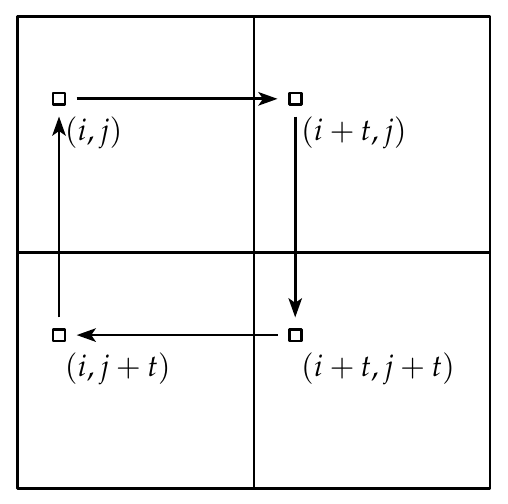
>
> En utilisant ce principe, écrire le code d'une fonction `rotation(x=0, y=0, t=512)` pour qu'elle effectue la rotation d'un quart de tour du carré de côté t dont le coin supérieur droit a pour coordonnées x et y.

> ✏️ **Coquille probable dans le sujet :** « coin **supérieur droit** ». Avec `x = 0, y = 0` et le schéma, il s'agit du coin **supérieur gauche** (le pixel `(0, 0)` est en haut à gauche).

#### ✅ RÉSOLUTION

In [4]:
def rotation(x=0, y=0, t=TAILLE):          # t=512 avec la vraie image
    if t == 1:
        return
    m = t // 2
    # 1. on tourne récursivement les 4 sous-carrés
    rotation(x, y, m)                      # haut-gauche
    rotation(x + m, y, m)                  # haut-droite
    rotation(x, y + m, m)                  # bas-gauche
    rotation(x + m, y + m, m)              # bas-droite
    # 2. on permute les 4 sous-carrés, pixel par pixel
    for i in range(x, x + m):
        for j in range(y, y + m):
            hg = get_pixel(i, j)
            hd = get_pixel(i + m, j)
            bd = get_pixel(i + m, j + m)
            bg = get_pixel(i, j + m)
            set_pixel(i + m, j, hg)        # haut-gauche -> haut-droite
            set_pixel(i + m, j + m, hd)    # haut-droite -> bas-droite
            set_pixel(i, j + m, bd)        # bas-droite  -> bas-gauche
            set_pixel(i, j, bg)            # bas-gauche  -> haut-gauche
    update()


remet_image_tournee()
execute(rotation)
montre("Après rotation (diviser pour régner) :")
assert IMAGE == IMAGE_ORIGINALE

Après rotation (diviser pour régner) :
  # # # # # # # #
  # . . . . . . .
  # . . . . . . .
  # # # # # # . .
  # . . . . . . .
  # . . . . . . .
  # . . . . . . .
  # . . . . . . o



*Vérification (non demandée) : les deux méthodes donnent la même image sur une image aléatoire 64 × 64.*

In [5]:
from random import randint, seed
seed(3)
TAILLE = 64
DEPART = [[randint(0, 9) for _ in range(TAILLE)] for _ in range(TAILLE)]

IMAGE = [ligne[:] for ligne in DEPART]
rotation_tab()
resultat_tab = [ligne[:] for ligne in IMAGE]

IMAGE = [ligne[:] for ligne in DEPART]
rotation(0, 0, TAILLE)
assert IMAGE == resultat_tab
print("Les deux méthodes donnent la même image ✔")

TAILLE = 8

Les deux méthodes donnent la même image ✔


#### 💡 EXPLICATION PÉDAGOGIQUE

**Pourquoi ça marche ?** Tourner toute l'image d'un quart de tour revient à :
- tourner **chaque quart** d'un quart de tour (le contenu de chaque carré est orienté correctement) ;
- puis **déplacer** les quarts : haut-gauche → haut-droite → bas-droite → bas-gauche → haut-gauche.

**La permutation :** pour chaque position `(i, j)` du carré haut-gauche, on fait **tourner 4 pixels** à la fois. On les lit d'abord tous les 4 dans des variables, puis on les réécrit chacun à sa nouvelle place. On n'a besoin que de **4 variables**, et non d'un tableau de toute l'image : le coût en mémoire est négligeable.

**Paramètres :** `rotation(x, y, t)` tourne le carré de côté `t` dont le coin a pour coordonnées `(x, y)`. Dans le code, `m = t // 2` est le côté des 4 sous-carrés (c'est le `t` du schéma de l'énoncé).

**Cas de base :** un carré de côté 1 (un seul pixel) n'a pas besoin d'être tourné.

---
# Avec le vrai module `turnbuffon.py`

Placer `turnbuffon.py` (distribué en classe) et `turnbuffon.png` (dans ce dossier) dans le même dossier, puis lancer **sur son ordinateur** (pygame ouvre une fenêtre, ce qui ne marche pas dans Binder ou Colab) :

```python
from turnbuffon import *

TAILLE = 512

def rotation(x=0, y=0, t=512):
    ...   # le code ci-dessus

execute(rotation)
```

#### 💡 EXPLICATION PÉDAGOGIQUE

Avec `update()` à la fin de chaque appel, on **voit** l'algorithme travailler : d'abord de tout petits carrés tournent, puis des carrés de plus en plus grands.

**Bilan des deux méthodes :**

| | `rotation_tab` | `rotation` (diviser pour régner) |
|:---|:---|:---|
| Mémoire supplémentaire | toute l'image (≈ 1 Mo, bien plus en Python) | 4 variables (+ la pile des appels récursifs : $\log(512) = 9$ niveaux) |
| Nombre de lectures et d'écritures | $N^2$ | $N^2$ à chaque niveau, soit $N^2 \log(N)$ en tout |

Ici, « diviser pour régner » **économise la mémoire**, au prix d'un peu plus de calculs.